# Titanic Dataset: Exploratory Data Analysis & Feature Engineering

This notebook performs EDA and feature engineering on the Titanic dataset to prepare it for machine learning models.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler


# Set style
sns.set_theme(style="whitegrid")
%matplotlib inline

In [4]:
# Load the cleaned dataset
df = pd.read_csv('../data/titanic_cleaned.csv')
print("Dataset Loaded Successfully!")
df.head()

Dataset Loaded Successfully!


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,False,False,True
1,1,1,1,38.0,1,0,71.2833,True,False,False
2,1,3,1,26.0,0,0,7.9250,False,False,True
3,1,1,1,35.0,1,0,53.1000,False,False,True
4,0,3,0,35.0,0,0,8.0500,False,False,True


## 1. Descriptive Statistics

In [5]:
print("--- Descriptive Statistics ---")
df.describe()

--- Descriptive Statistics ---


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,0.352413,29.361582,0.523008,0.381594,32.204208
std,0.486592,0.836071,0.477990,13.019697,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,0.000000,22.000000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,0.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,1.000000,35.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,1.000000,80.000000,8.000000,6.000000,512.329200


## 2. Visualizations: Distributions

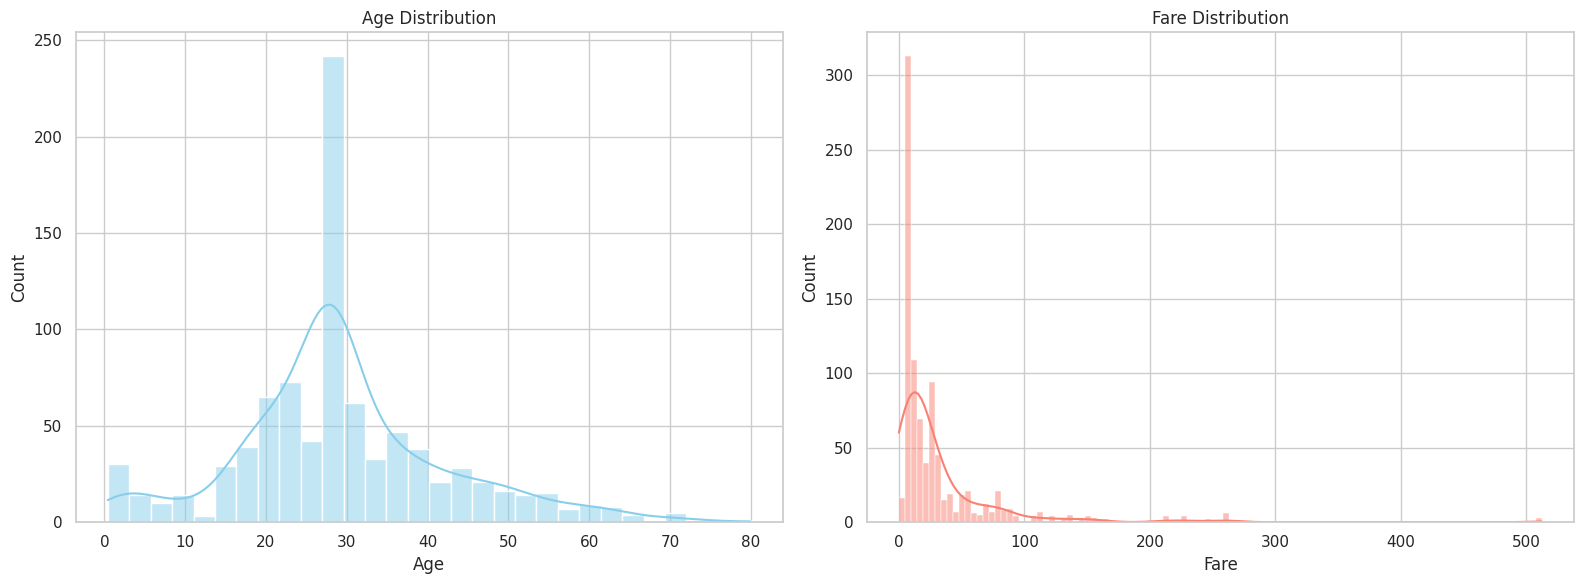

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Age Distribution
sns.histplot(df['Age'], kde=True, color='skyblue', ax=axes[0])
axes[0].set_title('Age Distribution')

# Fare Distribution
sns.histplot(df['Fare'], kde=True, color='salmon', ax=axes[1])
axes[1].set_title('Fare Distribution')

plt.tight_layout()
plt.show()

## 3. Visualizations: Survival Rates

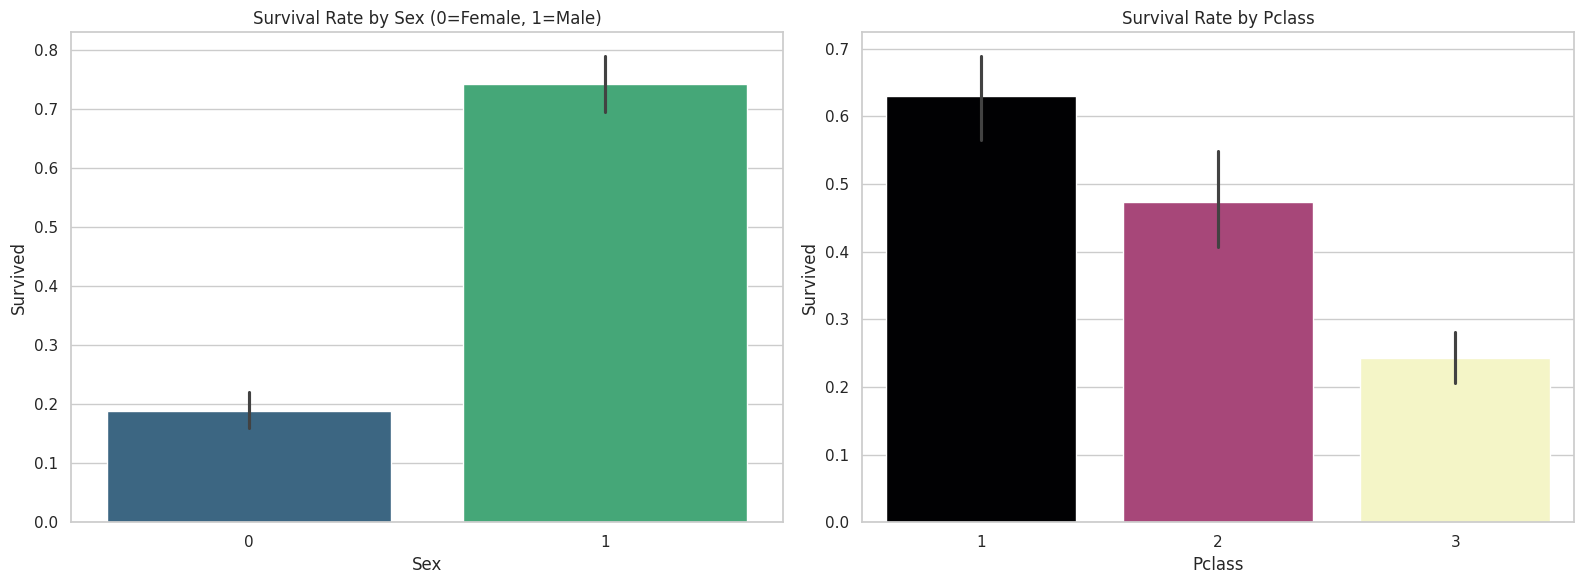

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Survival Rate by Sex
sns.barplot(x='Sex', y='Survived', data=df, palette='viridis', hue='Sex', legend=False, ax=axes[0])
axes[0].set_title('Survival Rate by Sex (0=Female, 1=Male)')

# Survival Rate by Pclass
sns.barplot(x='Pclass', y='Survived', data=df, palette='magma', hue='Pclass', legend=False, ax=axes[1])
axes[1].set_title('Survival Rate by Pclass')

plt.tight_layout()
plt.show()

## 4. Correlation Heatmap

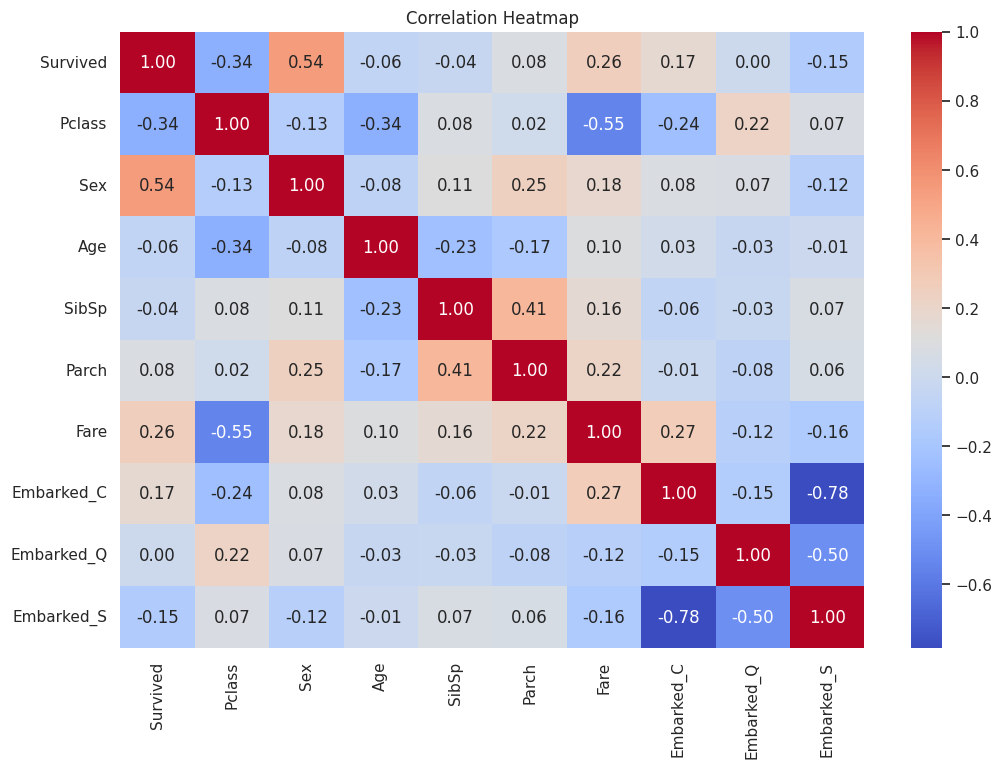

In [8]:
plt.figure(figsize=(12, 8))
numeric_df = df.select_dtypes(include=[np.number, bool])
correlation = numeric_df.corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

## 5. Feature Engineering

In [9]:
print("--- Performing Feature Engineering ---")
df_eng = df.copy()

# 1. Family Size
df_eng['FamilySize'] = df_eng['SibSp'] + df_eng['Parch'] + 1

# 2. IsAlone
df_eng['IsAlone'] = (df_eng['FamilySize'] == 1).astype(int)

# 3. Age Binning
df_eng['AgeBin'] = pd.cut(df_eng['Age'], bins=[0, 12, 20, 40, 60, 100], labels=['Child', 'Teen', 'Adult', 'MiddleAge', 'Senior'])
df_eng['AgeBin_Code'] = df_eng['AgeBin'].cat.codes

# 4. Scaling
scaler = StandardScaler()
df_eng[['Age', 'Fare']] = scaler.fit_transform(df_eng[['Age', 'Fare']])

# Cleanup
df_eng = df_eng.drop(columns=['AgeBin'])

print("Feature engineering complete.")
df_eng.head()

--- Performing Feature Engineering ---
Feature engineering complete.


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S,FamilySize,IsAlone,AgeBin_Code
0,0,3,0,-0.565736,1,0,-0.502445,False,False,True,2,0,2
1,1,1,1,0.663861,1,0,0.786845,True,False,False,2,0,2
2,1,3,1,-0.258337,0,0,-0.488854,False,False,True,1,1,2
3,1,1,1,0.433312,1,0,0.420730,False,False,True,2,0,2
4,0,3,0,0.433312,0,0,-0.486337,False,False,True,1,1,2


## 6. Save Result

In [10]:
df_eng.to_csv('../data/titanic_features.csv', index=False)
print("New dataset saved to data/titanic_features.csv")
print(f"Final Shape: {df_eng.shape}")

New dataset saved to data/titanic_features.csv
Final Shape: (891, 13)
